In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
dataset = pd.read_csv('Salary_Data.csv')
X = dataset.iloc[:, :-1].values
y = dataset.iloc[:, -1].values

In [9]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 1/3, random_state = 0)

In [ ]:
from sklearn.linear_model import LinearRegression
regressor = LinearRegression()
regressor.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[9345.94]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.682e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[11.32]


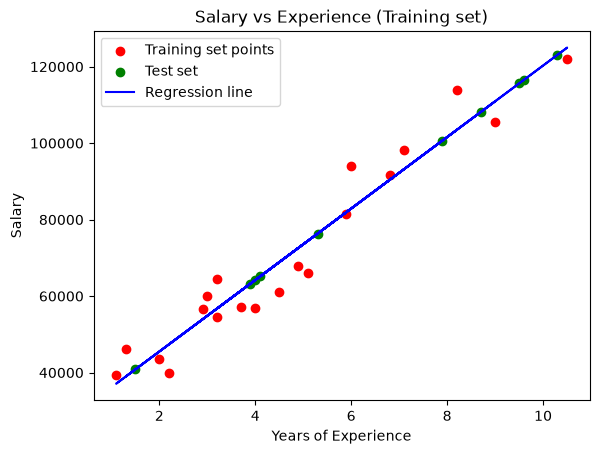

In [26]:
# Visualising the Training set results
plt.scatter(X_train, y_train, color = 'red', label = 'Training set points')
plt.scatter(X_test, regressor.predict(X_test), color = 'green', label = 'Test set')

plt.plot(X_train, regressor.predict(X_train), color = 'blue', label = 'Regression line')
plt.title('Salary vs Experience (Training set)')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.legend()
plt.show()

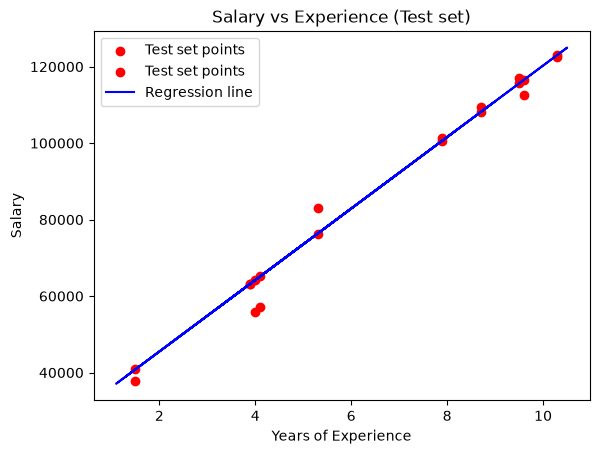

In [32]:
# Visualising the Test set results
plt.scatter(X_test, y_test, color = 'red', label = 'Test set points')
plt.scatter(X_test, regressor.predict(X_test), color = 'red', label = 'Test set points')
plt.plot(X_train, regressor.predict(X_train), color = 'blue', label = 'Regression line')
plt.title('Salary vs Experience (Test set)')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.legend()
plt.show()

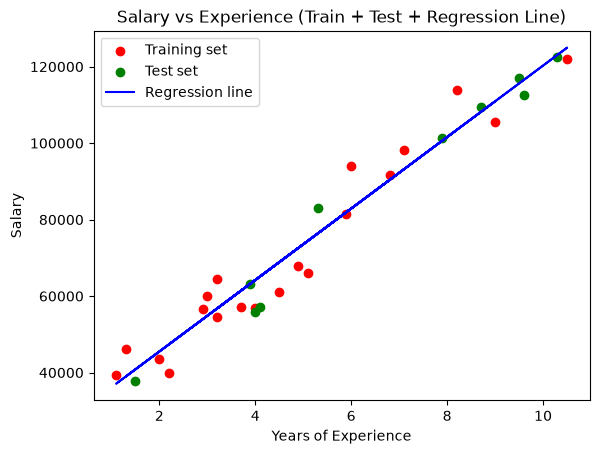

In [20]:
# Visualising Both Training & Test sets with the Regression line
plt.scatter(X_train, y_train, color = 'red', label = 'Training set')
plt.scatter(X_test, y_test, color = 'green', label = 'Test set')
plt.plot(X_train, regressor.predict(X_train), color = 'blue', label = 'Regression line')
plt.title('Salary vs Experience (Train + Test + Regression Line)')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.legend()
plt.show()

In [21]:
# Predicting the Test set results
y_pred = regressor.predict(X_test)

# Comparing Real vs Predicted values in a beautiful DataFrame
comparison_df = pd.DataFrame({
    'Real Salary (y_test)': np.round(y_test, 2),
    'Predicted Salary (y_pred)': np.round(y_pred, 2),
    'Difference (y_test - y_pred)': np.round(y_test - y_pred, 2)
})

comparison_df

,Real Salary (y_test),Predicted Salary (y_pred),Difference (y_test - y_pred)
0,37731.0,40835.11,-3104.11
1,122391.0,123079.40,-688.40
2,57081.0,65134.56,-8053.56
3,63218.0,63265.37,-47.37
4,116969.0,115602.65,1366.35
5,109431.0,108125.89,1305.11
6,112635.0,116537.24,-3902.24
7,55794.0,64199.96,-8405.96
8,83088.0,76349.69,6738.31
9,101302.0,100649.14,652.86


In [22]:
# 1. Predicting for a single value (e.g., 12 years of experience)
# Note: Double brackets [[12]] are required because predict() expects a 2D array: (number of observations, number of features)
single_prediction = regressor.predict([[12]])
print(f"Predicted salary for 12 years of experience: ${single_prediction[0]:,.2f}")

# 2. Predicting for multiple custom values in an array
new_experience = np.array([[2.5], [6.5], [12], [15]])
new_salaries = regressor.predict(new_experience)

# Displaying custom predictions in a DataFrame
custom_results_df = pd.DataFrame({
    'Years of Experience': new_experience.flatten(),
    'Predicted Salary': np.round(new_salaries, 2)
})

custom_results_df

Predicted salary for 12 years of experience: $138,967.50


,Years of Experience,Predicted Salary
0,2.5,50181.05
1,6.5,87564.82
2,12.0,138967.50
3,15.0,167005.33
